# 📚 Apuntes de estudio — Procesos estocásticos, estacionariedad, FAC y FACP
### Notebook de la profesora Beatriz Berríos P. con explicaciones agregadas

**Cómo leer este archivo**

| Lo que ves | Quién lo escribió |
|---|---|
| Todas las celdas de código y los textos de teoría numerados (1, 2, 3…) | **La profe, tal cual**, con sus resultados y gráficos |
| 📝 **Apunte** | Yo: qué significa la materia en palabras simples y qué hace cada línea |
| 📊 **Cómo leer el gráfico / la tabla** | Yo: qué mirar y cómo interpretarlo, con los resultados que obtuvo la profe |
| 🔁 **Si en el control me cambian…** | Yo: qué líneas modificar |
| ⚠️ **Ojo** | Yo: trampas y errores típicos |
| ✅ **Autoevaluación** | Yo: preguntas con respuesta oculta |

> No modifiqué ni agregué código. Los gráficos que ves ya ejecutados son los de la profe; si vuelves a ejecutar, la parte simulada da exactamente lo mismo (lo comprobé) y la parte del Banco Mundial puede cambiar levemente si el Banco actualiza los datos.

## 🗺️ ¿De qué trata esta clase? (la idea en 1 minuto)

En las clases anteriores **pronosticábamos** (SES, Holt, Holt-Winters). Esta clase responde una pregunta previa: **¿la serie se comporta de forma "estable" en el tiempo o no?** Eso se llama **estacionariedad**, y es la condición que necesitan muchos modelos (por ejemplo ARIMA) para funcionar bien.

El camino de la clase es:

1. **Proceso estocástico:** la serie es el resultado de un mecanismo aleatorio.
2. **Dos ejemplos simulados:** el **ruido blanco** (estacionario, sin memoria) y la **caminata aleatoria** (no estacionaria, acumula choques).
3. **Datos reales de Chile:** el **PIB real** (nivel, con tendencia) y su **crecimiento anual** (fluctúa alrededor de un valor).
4. **Herramientas para decidir si una serie es estacionaria:**
   - mirar el gráfico;
   - **media y varianza móviles**;
   - **FAC y FACP** (autocorrelaciones);
   - **diagramas de rezago**;
   - **pruebas ADF y KPSS**;
   - **prueba de Ljung-Box** (¿es ruido blanco?).
5. **Arreglo:** si la serie no es estacionaria, se **transforma** (logaritmo) y se **diferencia** (crecimiento).

**La conclusión de toda la clase con los datos de la profe:**

| Serie | ¿Estacionaria? | Por qué |
|---|---|---|
| log(PIB real) — el **nivel** | ❌ No | Tendencia creciente, FAC que baja lento, ADF no rechaza raíz unitaria, KPSS rechaza estacionariedad |
| Crecimiento del PIB — la **diferencia** | ✅ Sí | Oscila alrededor de ~4%, FAC dentro de las bandas, ADF rechaza raíz unitaria, KPSS no rechaza estacionariedad |

🔗 **Conexión con la clase anterior:** en Holt-Winters el tipo de cambio tuvo **α ≈ 1** y SES casi empató con todos. Eso pasa porque el tipo de cambio se parece a una **caminata aleatoria**, que es exactamente lo que estudia esta clase.

# Procesos estocásticos, estacionariedad, FAC y FACP

## Teoría y práctica con Python y datos del Banco Mundial

Este notebook utiliza dos series oficiales de Chile obtenidas mediante la API V2 del Banco Mundial:

- `NY.GDP.MKTP.KD`: PIB real, precios constantes de 2015 en US$.
- `NY.GDP.MKTP.KD.ZG`: crecimiento anual del PIB real, porcentaje.

La comparación es didácticamente útil: el nivel del PIB suele presentar tendencia, mientras que su crecimiento fluctúa alrededor de un nivel más estable.

### Paquetes requeridos

```bash
python -m pip install pandas numpy matplotlib requests scipy statsmodels
```

La API del Banco Mundial no requiere una clave de autenticación.

## 1. ¿Qué es un proceso estocástico?

Un proceso estocástico es una colección de variables aleatorias ordenadas mediante un índice:

$$\{X_t:t\in T\}$$

	X_t: representa una variable aleatoria en el instante t.
	T: es el conjunto de períodos de tiempo considerados (años, meses, días, trimestres, etc.).


En series de tiempo, $t$ representa el tiempo. Antes de observar la serie, cada $X_t$ es una variable aleatoria. Después de observarla, obtenemos una realización:

$$x_1,x_2,\ldots,x_n$$

Esta secuencia observada constituye la serie temporal que analizamos en la práctica.

Ejemplos económicos: inflación mensual, tipo de cambio diario, desempleo trimestral y PIB anual.

El objetivo no consiste solo en describir cada valor. También interesa comprender la dependencia entre $X_t$ y sus valores pasados.

📝 **Apunte — proceso estocástico en palabras simples**

Imagina que **cada año** el PIB de Chile se "sortea" con una especie de dado muy complicado (que depende de la economía, del cobre, de crisis, etc.).

- **Antes** de que ocurra el año, el PIB de ese año es una **variable aleatoria** $X_t$: no sabemos cuánto va a ser.
- El **proceso estocástico** $\{X_t\}$ es el conjunto de todos esos "dados", uno por cada período.
- **Después** de que pasan los años, vemos un solo resultado de cada dado: $x_1, x_2, \ldots, x_n$. Eso es la **realización**, o sea, **la serie de tiempo que tenemos en Excel**.

👉 Lo importante: **solo vemos UNA realización** (la historia no se repite). Por eso necesitamos suponer que el mecanismo es "estable" en el tiempo (estacionariedad) para poder aprender de los datos pasados.

👉 La última frase de la profe es clave: no solo interesa cada valor, sino **cómo depende $X_t$ de sus valores pasados** ($X_{t-1}$, $X_{t-2}$…). Esa dependencia es lo que miden la FAC y la FACP.

In [1]:
# 1. Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', '{:,.3f}'.format)

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


📝 **Apunte — librerías** (qué trae cada una)

| Línea | Para qué sirve en esta clase |
|---|---|
| `numpy`, `pandas`, `matplotlib` | Números, tablas y gráficos (igual que siempre) |
| `requests` | Descargar datos del Banco Mundial |
| `from scipy import stats` | Estadística (se importa, pero en este notebook no se usa directamente) |
| `plot_acf, plot_pacf` | Dibujan la **FAC** y la **FACP** |
| `adfuller, kpss` | Las **pruebas** ADF y KPSS de estacionariedad |
| `acorr_ljungbox` | La **prueba de Ljung-Box** (¿es ruido blanco?) |
| `plt.style.use('seaborn-v0_8-whitegrid')` | Estilo visual: fondo blanco con cuadrícula |
| `pd.set_option('display.float_format', '{:,.3f}'.format)` | Muestra los números con 3 decimales y separador de miles. Por eso el PIB se ve como `273,483,125,955.671` |

⚠️ **Ojo:** si sale `OSError` con el estilo `seaborn-v0_8-whitegrid`, tu matplotlib es muy antiguo: actualízalo con `%pip install -U matplotlib`. Si falta un paquete: `%pip install statsmodels scipy requests`.

## 2. Dos procesos simulados

### Ruido blanco

Un ruido blanco débil $\varepsilon_t$ satisface:

$$E(\varepsilon_t)=0,\qquad Var(\varepsilon_t)=\sigma^2,\qquad Cov(\varepsilon_t,\varepsilon_{t-k})=0\quad(k\neq0)$$

Sus observaciones pueden ser grandes o pequeñas, pero no presentan una estructura lineal predecible.

### Caminata aleatoria

$$X_t=X_{t-1}+\varepsilon_t$$

Los choques se acumulan. Por eso la caminata aleatoria no vuelve automáticamente a una media fija y no es estacionaria en nivel. Su primera diferencia sí es ruido blanco:

$$\Delta X_t=X_t-X_{t-1}=\varepsilon_t$$

📝 **Apunte — ruido blanco y caminata aleatoria**

**Ruido blanco $\varepsilon_t$** = valores **al azar e independientes del pasado**. Las 3 condiciones de la fórmula dicen:
- $E(\varepsilon_t)=0$ → en promedio es cero;
- $Var(\varepsilon_t)=\sigma^2$ → su dispersión es siempre la misma;
- $Cov(\varepsilon_t,\varepsilon_{t-k})=0$ → **lo de hoy no tiene relación con lo de ayer**. Saber el pasado **no ayuda a predecir**.

Ejemplo cotidiano: lanzar una moneda cada día. Que ayer saliera cara no dice nada de hoy.

**Caminata aleatoria** $X_t=X_{t-1}+\varepsilon_t$ = **"hoy = ayer + un choque al azar"**.
- Ejemplo: una persona que da un paso al azar (adelante o atrás) cada segundo. Su **posición** es una caminata aleatoria; cada **paso** es ruido blanco.
- Los choques **se acumulan**: si hubo varios pasos hacia adelante, se queda lejos; **no tiene una "casa" a la que volver** (no vuelve a una media fija). Por eso **no es estacionaria**.
- Si miramos solo **los pasos** (la diferencia $X_t - X_{t-1}$), recuperamos el ruido blanco: $\Delta X_t=\varepsilon_t$. **Diferenciar "arregla" la caminata aleatoria.**

| | Ruido blanco | Caminata aleatoria |
|---|---|---|
| Fórmula | $\varepsilon_t$ | $X_t = X_{t-1} + \varepsilon_t$ |
| ¿Vuelve a su media? | Sí, siempre ronda el 0 | No, se puede alejar indefinidamente |
| ¿Memoria? | Ninguna | Total: arrastra todos los choques pasados |
| ¿Estacionaria? | ✅ Sí | ❌ No (pero su **diferencia** sí) |
| FAC | Barras dentro de las bandas | Barras altas que bajan muy lento |

🔗 Esto también se llama **raíz unitaria**: en $X_t = \phi X_{t-1} + \varepsilon_t$, si $\phi = 1$ (la "raíz" vale 1) es una caminata aleatoria. Si $|\phi|<1$, la serie vuelve a su media y es estacionaria.

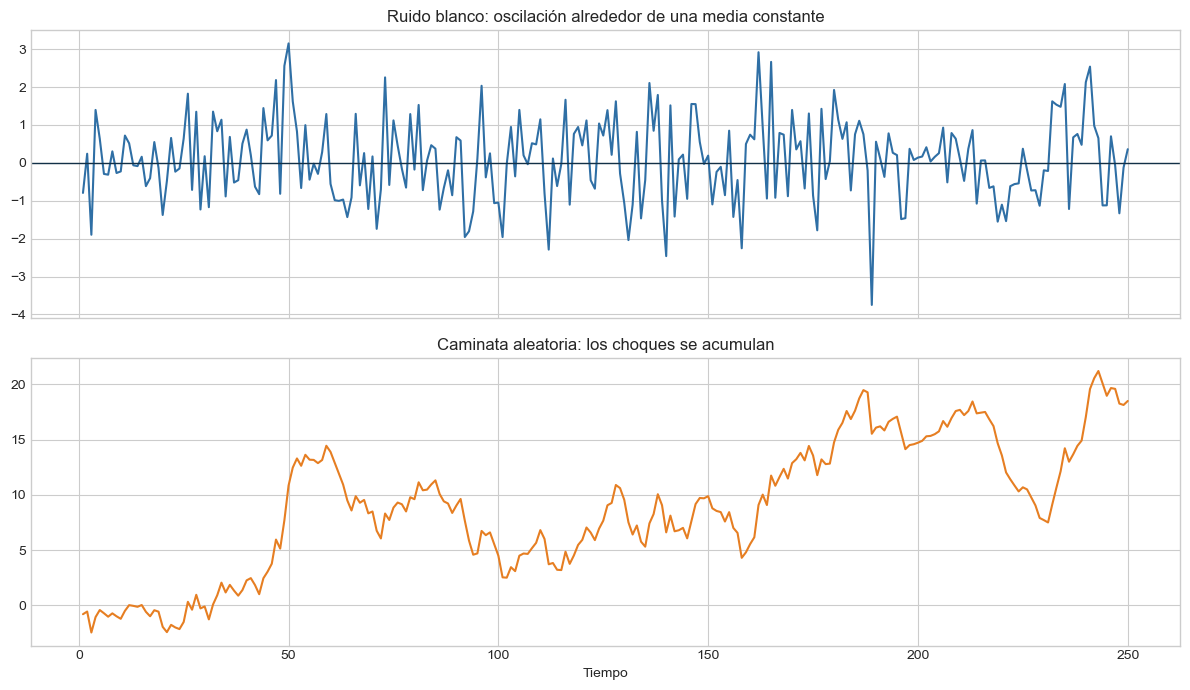

Media del ruido blanco: 0.074
Varianza del ruido blanco: 1.138
Media de la caminata: 8.898


In [3]:
# 2. Simulación reproducible
rng = np.random.default_rng(2026)
n = 250
ruido_blanco = rng.normal(loc=0, scale=1, size=n)
caminata_aleatoria = np.cumsum(ruido_blanco)
tiempo = np.arange(1, n + 1)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(tiempo, ruido_blanco, color='#2F6FA5')
axes[0].axhline(0, color='#123047', linewidth=1)
axes[0].set_title('Ruido blanco: oscilación alrededor de una media constante')
axes[1].plot(tiempo, caminata_aleatoria, color='#E67E22')
axes[1].set_title('Caminata aleatoria: los choques se acumulan')
axes[1].set_xlabel('Tiempo')
plt.tight_layout()
plt.show()

print('Media del ruido blanco:', round(ruido_blanco.mean(), 3))
print('Varianza del ruido blanco:', round(ruido_blanco.var(), 3))
print('Media de la caminata:', round(caminata_aleatoria.mean(), 3))

📝 **Apunte — el código de la simulación**

- `rng = np.random.default_rng(2026)` → generador de números aleatorios con **semilla 2026** (reproducible: siempre da lo mismo). Es la versión moderna de `np.random.seed`.
- `n = 250` → 250 períodos.
- `rng.normal(loc=0, scale=1, size=n)` → 250 números de una normal con media 0 y desviación 1: **el ruido blanco**.
- `np.cumsum(ruido_blanco)` → **suma acumulada**: $X_1=\varepsilon_1$, $X_2=\varepsilon_1+\varepsilon_2$, … Eso es justamente la **caminata aleatoria** (acumular los choques).
- `tiempo = np.arange(1, n + 1)` → eje X: 1, 2, …, 250.
- `plt.subplots(2, 1, ..., sharex=True)` → 2 gráficos uno sobre otro con el mismo eje X.
- `axhline(0, ...)` → línea horizontal en 0 (la media teórica del ruido).

📊 **Cómo leer el gráfico**

- **Arriba (ruido blanco, azul):** sube y baja **alrededor de 0** todo el tiempo, con una dispersión parecida al principio y al final. No se ve ninguna tendencia ni ola. Así se ve algo **estacionario**.
- **Abajo (caminata, naranja):** parte cerca de 0, **sube a ~14** cerca de t=60, baja a ~3 cerca de t=100 y termina en ~19-21. Da la impresión de "tendencias", pero **son puro azar acumulado**. No ronda ningún valor fijo → **no estacionaria**.

📊 **Cómo leer los números impresos**
- Media del ruido = **0,074** (≈ 0, como debe ser) y varianza = **1,138** (≈ 1, porque `scale=1`).
- Media de la caminata = **8,898**: este número **no significa nada estable**. Con otra semilla podría dar −15 o +30, porque la caminata no tiene una media fija.

🧪 **Prueba (Actividad 1.1):** cambia `2026` por otro número y vuelve a ejecutar. El ruido seguirá rondando 0; la caminata tomará un camino totalmente distinto.

💡 **Respuesta a la Actividad 1.4** (¿por qué una trayectoria suave puede ser no estacionaria?): la caminata se ve **más suave** que el ruido porque cada valor es el anterior más un pequeño choque, pero justamente por eso **arrastra todo su pasado** y su nivel deriva sin volver a una media. "Suave" no significa "estable".

## 3. Estacionariedad estricta y débil

### Estacionariedad estricta

La distribución conjunta no cambia si todas las observaciones se desplazan la misma cantidad de tiempo:

$$F(X_{t_1},\ldots,X_{t_k})=F(X_{t_1+h},\ldots,X_{t_k+h})$$

Es una condición fuerte y difícil de verificar empíricamente.

### Estacionariedad débil o de segundo orden

Se requieren tres condiciones:

1. Media constante:
   $$E(X_t)=\mu$$
2. Varianza finita y constante:
   $$Var(X_t)=\sigma^2<\infty$$
3. Covarianza dependiente solo del rezago:
   $$Cov(X_t,X_{t-k})=\gamma_k$$

Una serie puede tener distribución no normal y aun así ser débilmente estacionaria. La normalidad y la estacionariedad son conceptos distintos.

📝 **Apunte — estacionariedad en palabras simples**

**Estacionaria = "las reglas del juego no cambian con el tiempo".** Si tomas un pedazo de la serie de los años 70 y otro de los 2010, deberían "parecerse" estadísticamente.

**Estricta:** *toda* la distribución es igual en cualquier momento. Es muy exigente; en la práctica casi no se verifica.

**Débil (la que se usa en la práctica):** basta con 3 condiciones:

| Condición | En palabras | Cómo se ve en el gráfico | Ejemplo que la **rompe** |
|---|---|---|---|
| 1. Media constante | La serie ronda siempre el mismo valor | Oscila alrededor de una línea horizontal | El PIB, que crece año a año (tendencia) |
| 2. Varianza constante | Las subidas y bajadas tienen el mismo tamaño siempre | El "ancho" de la nube no cambia | Una serie que de repente se vuelve mucho más volátil |
| 3. Covarianza depende solo del rezago | La relación entre hoy y hace *k* períodos es la misma en cualquier época | (se ve en la FAC) | Una serie cuya memoria cambia según la época |

$\gamma_k$ es la **autocovarianza** en el rezago *k*: cuánto se mueven juntos $X_t$ y $X_{t-k}$. Si la divides por la varianza obtienes la **autocorrelación** $\rho_k$ (lo que dibuja la FAC).

⚠️ **Frase que suelen preguntar:** *"Una serie puede no ser normal y aun así ser estacionaria"*. Normalidad = forma de la campana; estacionariedad = estabilidad en el tiempo. **Son cosas distintas.**

## 4. Descarga desde la API del Banco Mundial

La consulta se realiza directamente contra `api.worldbank.org`. Se conservan únicamente observaciones no nulas y se ordenan cronológicamente.

La fecha final se deja abierta para que el notebook recupere la versión más reciente disponible cuando se ejecute nuevamente.

In [4]:
# 3. Serie 1: PIB real de Chile, nivel
url_nivel = 'https://api.worldbank.org/v2/country/CHL/indicator/NY.GDP.MKTP.KD'
params_nivel = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_nivel = requests.get(url_nivel, params=params_nivel, timeout=60)
respuesta_nivel.raise_for_status()
json_nivel = respuesta_nivel.json()

if not isinstance(json_nivel, list) or len(json_nivel) < 2 or json_nivel[1] is None:
    raise RuntimeError('La API no devolvió el PIB real de Chile.')

datos_nivel = pd.DataFrame(json_nivel[1])[['date', 'value']]
datos_nivel.columns = ['anio', 'pib_real']
datos_nivel['anio'] = pd.to_numeric(datos_nivel['anio'], errors='coerce')
datos_nivel['pib_real'] = pd.to_numeric(datos_nivel['pib_real'], errors='coerce')
datos_nivel = datos_nivel.dropna().sort_values('anio')

# 4. Serie 2: crecimiento anual del PIB real
url_crecimiento = 'https://api.worldbank.org/v2/country/CHL/indicator/NY.GDP.MKTP.KD.ZG'
params_crecimiento = {
    'format': 'json',
    'date': '1960:2030',
    'per_page': 200,
}

respuesta_crecimiento = requests.get(
    url_crecimiento,
    params=params_crecimiento,
    timeout=60,
)
respuesta_crecimiento.raise_for_status()
json_crecimiento = respuesta_crecimiento.json()

if not isinstance(json_crecimiento, list) or len(json_crecimiento) < 2 or json_crecimiento[1] is None:
    raise RuntimeError('La API no devolvió el crecimiento del PIB de Chile.')

datos_crecimiento = pd.DataFrame(json_crecimiento[1])[['date', 'value']]
datos_crecimiento.columns = ['anio', 'crecimiento_pib']
datos_crecimiento['anio'] = pd.to_numeric(datos_crecimiento['anio'], errors='coerce')
datos_crecimiento['crecimiento_pib'] = pd.to_numeric(
    datos_crecimiento['crecimiento_pib'],
    errors='coerce',
)
datos_crecimiento = datos_crecimiento.dropna().sort_values('anio')

datos = pd.merge(datos_nivel, datos_crecimiento, on='anio', how='inner')
datos = datos.set_index('anio')

print('Primera observación:', datos.index.min())
print('Última observación:', datos.index.max())
print('Número de años:', len(datos))
print(datos.tail())

Primera observación: 1961
Última observación: 2025
Número de años: 65
                pib_real  crecimiento_pib
anio                                     
2021 273,483,125,955.671           11.337
2022 279,127,595,176.477            2.064
2023 281,017,358,307.658            0.677
2024 288,900,250,332.819            2.805
2025 296,005,043,455.575            2.459


📝 **Apunte — la descarga, paso a paso**

Se descargan **dos indicadores** de Chile (código `CHL`):
- `NY.GDP.MKTP.KD` → **PIB real** en dólares constantes de 2015 (el **nivel**).
- `NY.GDP.MKTP.KD.ZG` → **crecimiento anual** del PIB real en % (el **cambio**).

Para cada uno, el mismo procedimiento que en Holt-Winters:
1. `url_...` y `params_...`: dirección y parámetros (`'date': '1960:2030'` = todos los años disponibles; son datos **anuales**, por eso no hay `frequency`).
2. `requests.get(...)`, `raise_for_status()`, `.json()` → pedir, revisar y convertir la respuesta.
3. El `if not isinstance(...)` → si la API no devolvió datos, se detiene con un mensaje claro.
4. `pd.DataFrame(json_nivel[1])[['date', 'value']]` → tabla con año y valor (la parte `[1]` son los datos).
5. `.columns = ['anio', 'pib_real']` → renombra las columnas.
6. `pd.to_numeric(..., errors='coerce')` → convierte a número (lo que no se pueda, queda NaN).
7. `.dropna().sort_values('anio')` → bota vacíos y ordena del año más antiguo al más nuevo.

Después:
- `pd.merge(datos_nivel, datos_crecimiento, on='anio', how='inner')` → **une las dos tablas por año**. `inner` = se quedan solo los años que están en **ambas**.
- `datos.set_index('anio')` → el año pasa a ser el índice.

📊 **Cómo leer la salida:** primer año **1961**, último **2025**, **65 años**. En 2025 el PIB real fue ≈ 296 mil millones de US$ de 2015 y creció 2,46%. Fíjate en **2021: +11,3%** (rebote después de la pandemia).

🔁 **Si en el control me cambian el país (Actividad 3):** hay que cambiar `CHL` en **las DOS URL** (`url_nivel` y `url_crecimiento`). Si cambias solo una, mezclarías PIB de un país con crecimiento de otro. Códigos: `ARG`, `PER`, `COL`, `MEX`, `BRA`. Cambia también los títulos de los gráficos que dicen "Chile".

## 5. Inspección gráfica de nivel y crecimiento

Se buscan señales incompatibles con la estacionariedad:

- tendencia en la media;
- cambio persistente de varianza;
- ciclos o quiebres prolongados;
- observaciones extremas;
- dependencia entre valores cercanos.

Una prueba estadística nunca reemplaza esta inspección inicial.

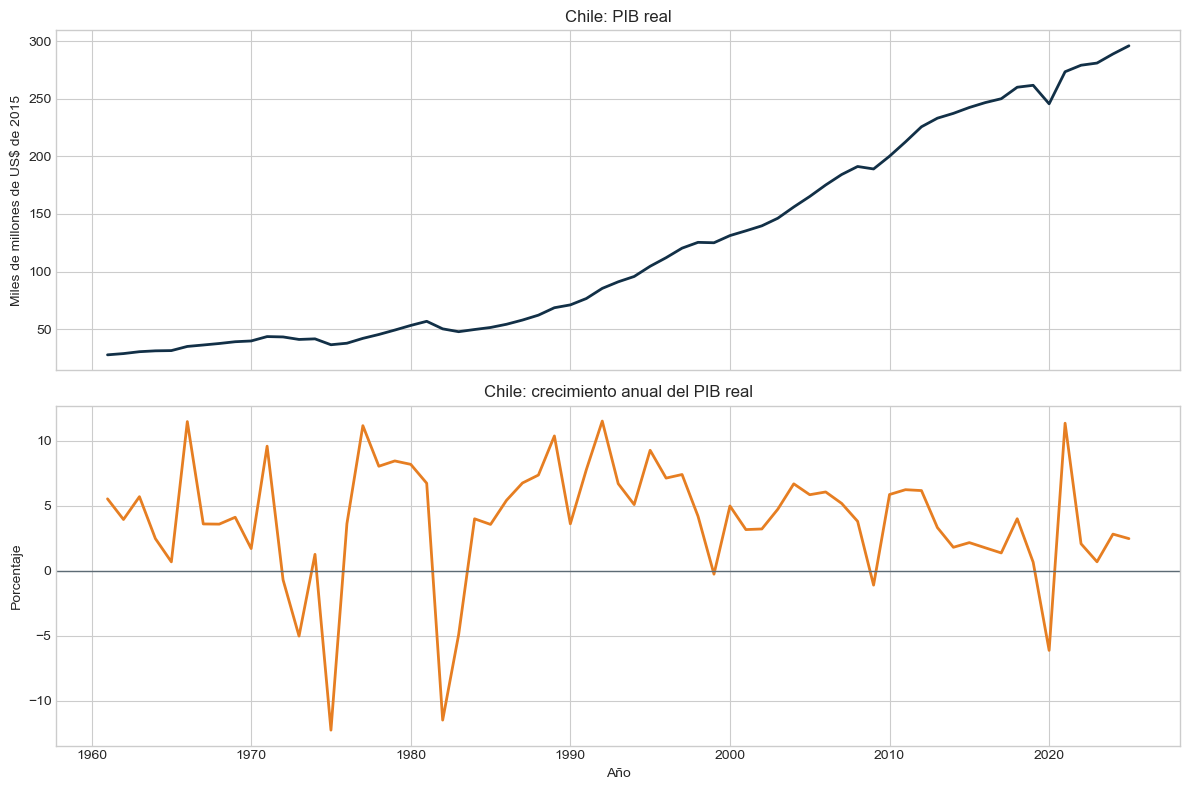

In [5]:
# 5. Gráficos de las series originales
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(datos.index, datos['pib_real'] / 1e9, color='#123047', linewidth=2)
axes[0].set_title('Chile: PIB real')
axes[0].set_ylabel('Miles de millones de US$ de 2015')

axes[1].plot(datos.index, datos['crecimiento_pib'], color='#E67E22', linewidth=2)
axes[1].axhline(0, color='#5D6B75', linewidth=1)
axes[1].set_title('Chile: crecimiento anual del PIB real')
axes[1].set_xlabel('Año')
axes[1].set_ylabel('Porcentaje')

plt.tight_layout()
plt.show()

📝 **Apunte:** dos gráficos (2 filas, 1 columna). El PIB se divide por `1e9` (mil millones) para que el eje sea legible. En el de crecimiento, `axhline(0)` marca el 0%: lo que está debajo son **recesiones** (el PIB cayó).

📊 **Cómo leer los gráficos de la profe**

**PIB real (arriba):** sube de ~30 a ~296 mil millones de US$. Tiene una **tendencia creciente clarísima** y la curva se "empina" con el tiempo (crecimiento casi exponencial). Caídas visibles en 1975, 1982-83, 2009 y 2020.
→ La media **no es constante** ⇒ **no estacionaria**.

**Crecimiento (abajo):** oscila **alrededor de 4-5%**, sin tendencia. Pero hay **valores extremos**:
- **1975 (≈ −12%)** y **1982 (≈ −11%)**: grandes crisis económicas.
- **2009 (≈ −1%)**: crisis financiera global.
- **2020 (≈ −6%)** y **2021 (≈ +11%)**: pandemia y rebote.

Además, se ve **más volátil antes de 1990** que después (las oscilaciones son más grandes). → La media parece estable, pero la varianza podría no serlo del todo. Esto se revisa en la siguiente sección.

✍️ **Respuesta tipo para la Actividad 2.1** ("describa sin aplicar pruebas"): *"El PIB real presenta una tendencia creciente persistente, por lo que su media no es constante. El crecimiento fluctúa alrededor de un nivel cercano a 4%, sin tendencia, aunque con valores extremos asociados a crisis (1975, 1982, 2009, 2020) y mayor volatilidad antes de 1990."*

## 6. Media y varianza móviles

Una forma visual de explorar la estacionariedad débil consiste en comparar estadísticas locales:

$$\bar X_t^{(w)}=\frac{1}{w}\sum_{j=0}^{w-1}X_{t-j}$$

Si la media o la varianza móvil cambian sistemáticamente, la hipótesis de estacionariedad resulta poco plausible. La ventana no produce una prueba formal; solo resume cambios locales.

📝 **Apunte — media y varianza móviles**

La fórmula dice: la media móvil en el año *t* es el **promedio de los últimos *w* años** (aquí *w* = 10). Es como mirar la serie por una "ventana" de 10 años que se va corriendo.

- Si la serie es estacionaria, el promedio y la varianza de cada ventana deberían ser **parecidos** en todas las épocas → las líneas móviles se ven **planas**.
- Si la media móvil **sube** (o la varianza cambia mucho), hay evidencia **en contra** de la estacionariedad.

⚠️ Es una **herramienta visual**, no una prueba formal.

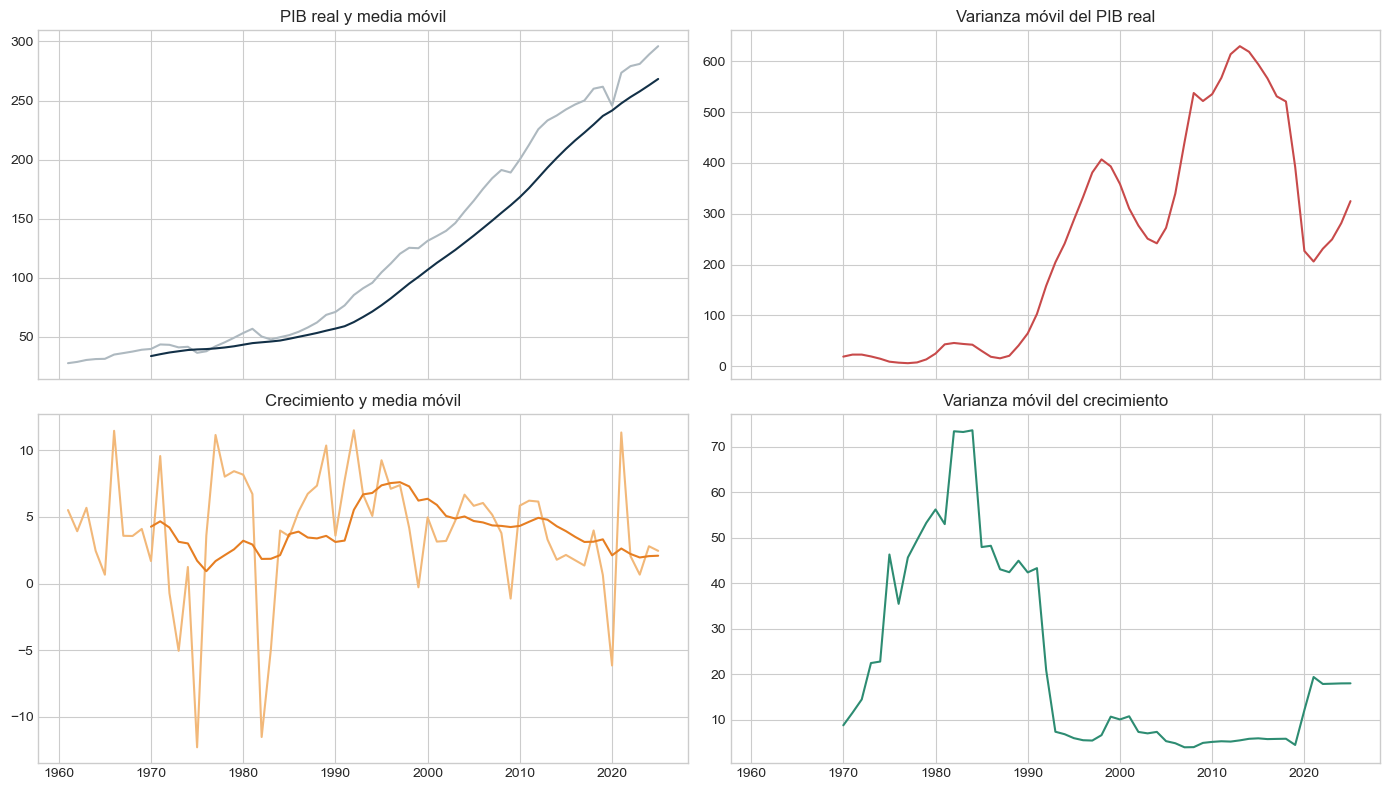

In [6]:
# 6. Estadísticas móviles de diez años
ventana = 10

datos['media_movil_nivel'] = datos['pib_real'].rolling(ventana).mean()
datos['var_movil_nivel'] = datos['pib_real'].rolling(ventana).var()
datos['media_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).mean()
datos['var_movil_crecimiento'] = datos['crecimiento_pib'].rolling(ventana).var()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes[0, 0].plot(datos.index, datos['pib_real'] / 1e9, color='#AEB9C0')
axes[0, 0].plot(datos.index, datos['media_movil_nivel'] / 1e9, color='#123047')
axes[0, 0].set_title('PIB real y media móvil')

axes[0, 1].plot(datos.index, datos['var_movil_nivel'] / 1e18, color='#C84A4A')
axes[0, 1].set_title('Varianza móvil del PIB real')

axes[1, 0].plot(datos.index, datos['crecimiento_pib'], color='#F2B879')
axes[1, 0].plot(datos.index, datos['media_movil_crecimiento'], color='#E67E22')
axes[1, 0].set_title('Crecimiento y media móvil')

axes[1, 1].plot(datos.index, datos['var_movil_crecimiento'], color='#2D8C72')
axes[1, 1].set_title('Varianza móvil del crecimiento')

plt.tight_layout()
plt.show()

📝 **Apunte — el código**

- `ventana = 10` → ventanas de 10 años.
- `.rolling(ventana).mean()` → media móvil; `.rolling(ventana).var()` → varianza móvil. Los **primeros 9 años quedan vacíos** (NaN) porque todavía no hay 10 datos; por eso las líneas oscuras empiezan en 1970.
- Se guardan como **nuevas columnas** de `datos`.
- `plt.subplots(2, 2, ...)` → grilla de 4 gráficos. `axes[0, 0]` = arriba izquierda, `axes[0, 1]` = arriba derecha, `axes[1, 0]` = abajo izquierda, `axes[1, 1]` = abajo derecha.
- La varianza del PIB se divide por `1e18` porque está en dólares **al cuadrado** (si el PIB se divide por 10⁹, su varianza se divide por 10⁹ × 10⁹ = 10¹⁸).

📊 **Cómo leer los 4 gráficos de la profe**

| Gráfico | Qué se ve | Conclusión |
|---|---|---|
| **PIB real y media móvil** (arriba izq.) | La media móvil (azul oscuro) **sube todo el tiempo** | Media **no constante** ❌ |
| **Varianza móvil del PIB** (arriba der.) | Casi 0 hasta 1990, luego sube a ~400 y ~600 | Varianza **no constante** ❌ (crece con el nivel) |
| **Crecimiento y media móvil** (abajo izq.) | La media móvil (naranja oscuro) se mueve **entre ~1% y ~7,5%**, sin tendencia persistente | Media **bastante estable** ✅ |
| **Varianza móvil del crecimiento** (abajo der.) | **Muy alta** en 1975-1992 (hasta ~73, por las crisis de 1975 y 1982), **muy baja** en 1993-2019 (~5) y sube en 2020-2021 (~18, pandemia) | La varianza **cambia por épocas** ⚠️ |

✍️ **Respuesta tipo para la Actividad 2.2:** *"La media y la varianza móviles del PIB real crecen sistemáticamente, lo que es incompatible con la estacionariedad. En el crecimiento, la media móvil se mantiene en un rango acotado sin tendencia, pero la varianza móvil cambia por períodos: es alta entre 1975 y 1992, por las crisis de 1975 y 1982, y baja después de 1993. El crecimiento es mucho más compatible con la estacionariedad que el nivel, aunque presenta episodios de volatilidad distinta."*

🔁 **Si me cambian la ventana:** `ventana = 5` hace las líneas más "nerviosas"; `ventana = 20` las hace más suaves y empiezan más tarde.

## 7. Transformación del nivel

El logaritmo convierte cambios proporcionales en diferencias aproximadamente aditivas. Para el PIB positivo:

$$g_t^{log}=100\,[\log(PIB_t)-\log(PIB_{t-1})]$$

Esta tasa logarítmica se aproxima al crecimiento porcentual publicado, aunque no coincide exactamente porque las definiciones y revisiones estadísticas pueden diferir.

📝 **Apunte — ¿por qué logaritmo y diferencia?**

Esto conecta con la **Clase de Transformaciones**: allí vimos que *"una diferencia en logaritmos ≈ cambio porcentual"*. Aquí se usa:

$$100\,[\log(PIB_t)-\log(PIB_{t-1})] \approx \text{crecimiento \% del PIB}$$

Ejemplo: PIB pasa de 100 a 103 → $100\,[\ln 103 - \ln 100] = 2{,}96 \approx 3\%$.

Dos pasos para volver estacionaria una serie como el PIB:
1. **Logaritmo:** convierte el crecimiento "exponencial" en una línea más recta y estabiliza la varianza (la que vimos crecer en la varianza móvil).
2. **Diferencia** (`.diff()`): quita la tendencia. Restar el valor del año anterior deja solo **el cambio**. Es lo mismo que pasaba con la caminata aleatoria: $\Delta X_t = \varepsilon_t$.

Correlación entre ambas medidas: 0.9992
      crecimiento_pib  crecimiento_log
anio                                  
2021           11.337           10.740
2022            2.064            2.043
2023            0.677            0.675
2024            2.805            2.767
2025            2.459            2.430


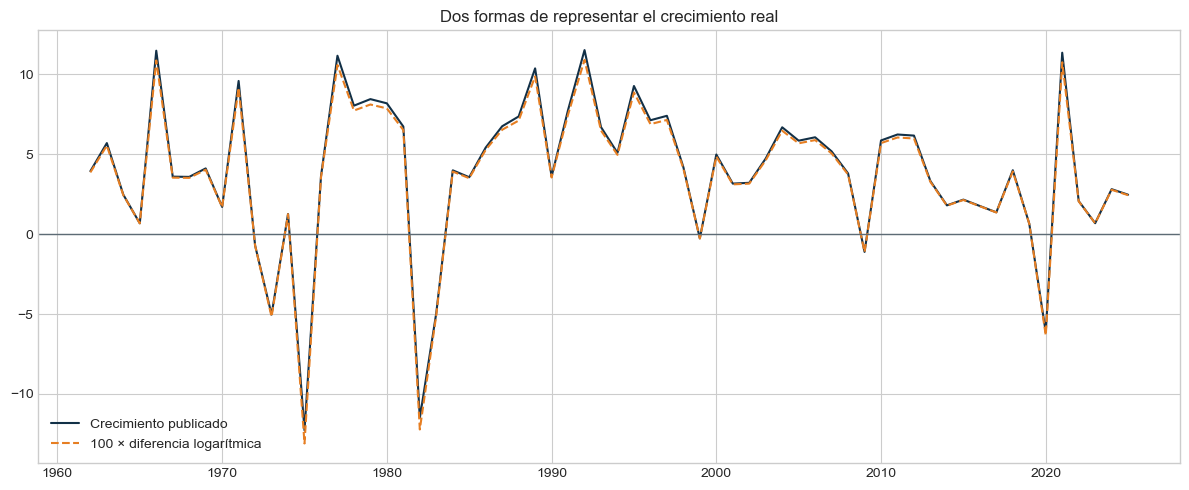

In [7]:
# 7. Logaritmo y primera diferencia logarítmica
datos['log_pib'] = np.log(datos['pib_real'])
datos['crecimiento_log'] = 100 * datos['log_pib'].diff()

comparacion_crecimiento = datos[
    ['crecimiento_pib', 'crecimiento_log']
].dropna()

correlacion_crecimientos = comparacion_crecimiento.corr().iloc[0, 1]

print('Correlación entre ambas medidas:', round(correlacion_crecimientos, 4))
print(comparacion_crecimiento.tail().round(3))

plt.figure(figsize=(12, 5))
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_pib'],
    label='Crecimiento publicado',
    color='#123047',
)
plt.plot(
    comparacion_crecimiento.index,
    comparacion_crecimiento['crecimiento_log'],
    label='100 × diferencia logarítmica',
    color='#E67E22',
    linestyle='--',
)
plt.axhline(0, color='#5D6B75', linewidth=1)
plt.title('Dos formas de representar el crecimiento real')
plt.legend()
plt.tight_layout()
plt.show()

📝 **Apunte — el código**

- `np.log(datos['pib_real'])` → logaritmo natural del PIB (nueva columna `log_pib`).
- `100 * datos['log_pib'].diff()` → `.diff()` calcula **valor de este año − valor del año anterior**; × 100 para que quede en %. El primer año queda NaN (no tiene año anterior).
- `datos[['crecimiento_pib', 'crecimiento_log']].dropna()` → tabla con las dos medidas, sin vacíos.
- `.corr().iloc[0, 1]` → matriz de correlación 2×2; `iloc[0, 1]` saca el número de la fila 0, columna 1 (la correlación entre las dos).
- El gráfico: línea **azul oscuro** = crecimiento publicado; línea **naranja punteada** (`linestyle='--'`) = la calculada con logaritmos.

📊 **Cómo interpretar**

- **Correlación = 0,9992** → prácticamente idénticas.
- Las dos líneas casi se superponen. Las **diferencias más grandes** están en los cambios grandes: 2021 → **11,34% vs 10,74%**; 1975 y 1982 en las caídas. En años "normales" (2023: 0,677 vs 0,675) son casi iguales.
- **¿Por qué?** La aproximación $\ln(1+g) \approx g$ funciona muy bien para cambios **pequeños** y empeora para cambios **grandes**. Además, el dato publicado puede tener revisiones y definiciones distintas (lo dice la profe).

✅ **Conclusión:** el crecimiento del PIB es, en la práctica, la **primera diferencia del log del PIB**. Por eso en el resto de la clase se comparan `log_pib` (nivel) y `crecimiento_pib` (diferencia).

## 8. Función de autocorrelación, FAC

La autocorrelación muestral en el rezago $k$ es:

$$\widehat\rho_k=Corr(X_t,X_{t-k})$$

Lectura básica:

| Patrón de la FAC | Interpretación posible |
|---|---|
| Caída lenta desde valores altos | Tendencia o raíz unitaria |
| Corte después del rezago $q$ | Compatible con un proceso MA($q$) |
| Decaimiento gradual | Compatible con dependencia autorregresiva |
| Picos en $m,2m,3m$ | Estacionalidad de período $m$ |
| Barras pequeñas dentro de bandas | Compatible con baja dependencia lineal |

Las bandas son aproximadas. Una barra aislada puede aparecer por azar cuando se examinan muchos rezagos.

📝 **Apunte — la FAC en palabras simples**

La **autocorrelación en el rezago *k*** responde: **¿qué tanto se parece la serie a sí misma *k* períodos atrás?**
- $\rho_1$ = correlación entre el valor de **este año** y el del **año pasado**.
- $\rho_2$ = entre este año y **hace 2 años**. Etc.
- Va de −1 a 1. Cerca de 1: "si el año pasado fue alto, este año también". Cerca de 0: el pasado no dice nada.

**Cómo leer el gráfico de la FAC** (`plot_acf`):
- **Eje X** = rezago *k* (1, 2, 3…). **Eje Y** = autocorrelación.
- Cada **palito con punto** = la autocorrelación en ese rezago.
- La **zona celeste** = banda de confianza del 95%. **Dentro** = no se distingue de 0 (no significativa). **Fuera** = autocorrelación significativa.

**La tabla de la profe, traducida:**

| Si la FAC… | Quiere decir… |
|---|---|
| Empieza cerca de 1 y **baja muy lento** | La serie tiene **tendencia o raíz unitaria** → **no estacionaria** (hay que diferenciar) |
| Tiene barras significativas hasta *q* y luego **se corta de golpe** | Podría ser un modelo **MA(q)** (*media móvil*: depende de choques pasados) |
| **Baja de a poco** (exponencialmente) | Podría ser un modelo **AR** (*autorregresivo*: depende de sus valores pasados) |
| Tiene picos en 12, 24, 36… (*m*, 2*m*, 3*m*) | **Estacionalidad** de período *m* |
| Todas las barras **dentro de la banda** | Casi no hay dependencia → parecido a **ruido blanco** |

⚠️ Con 15 rezagos y 95% de confianza, es normal que **1 barra se salga por azar**. No te alarmes por una barra aislada que apenas sale.

## 9. Función de autocorrelación parcial, FACP

La FACP en el rezago $k$ mide la relación entre $X_t$ y $X_{t-k}$ después de controlar los rezagos intermedios $1,\ldots,k-1$.

Lectura orientativa:

| Patrón de la FACP | Interpretación posible |
|---|---|
| Corte después del rezago $p$ | Compatible con AR($p$) |
| Decaimiento gradual | Compatible con un componente MA |
| Picos persistentes | Puede quedar tendencia, estacionalidad o estructura más compleja |

FAC y FACP ayudan a formular modelos candidatos. No determinan por sí solas el modelo definitivo.

📝 **Apunte — la FACP en palabras simples**

La **autocorrelación parcial** en el rezago *k* mide la relación **directa** entre $X_t$ y $X_{t-k}$, **quitando** el efecto de los rezagos intermedios.

Ejemplo: si este año se parece al año pasado, y el año pasado al antepasado, entonces este año también se parecerá "indirectamente" al antepasado. La **FAC** cuenta ese parecido indirecto; la **FACP** lo **descuenta** y deja solo lo directo.

| Si la FACP… | Quiere decir… |
|---|---|
| Tiene barras significativas hasta *p* y luego **se corta** | Compatible con **AR(p)**: la serie depende directamente de sus últimos *p* valores |
| **Baja de a poco** | Compatible con un componente **MA** |
| Tiene picos que persisten | Puede quedar tendencia, estacionalidad u otra estructura |

**Resumen para memorizar (Box-Jenkins):**

| Modelo | FAC | FACP |
|---|---|---|
| **AR(p)** | Decae gradualmente | **Se corta** después de *p* |
| **MA(q)** | **Se corta** después de *q* | Decae gradualmente |
| **Caminata aleatoria / tendencia** | Decae **muy lento** desde ~1 | Un solo pico grande (~1) en el rezago 1 |
| **Ruido blanco** | Todo dentro de las bandas | Todo dentro de las bandas |

La profe advierte: FAC y FACP **sugieren** modelos candidatos; no los determinan solas.

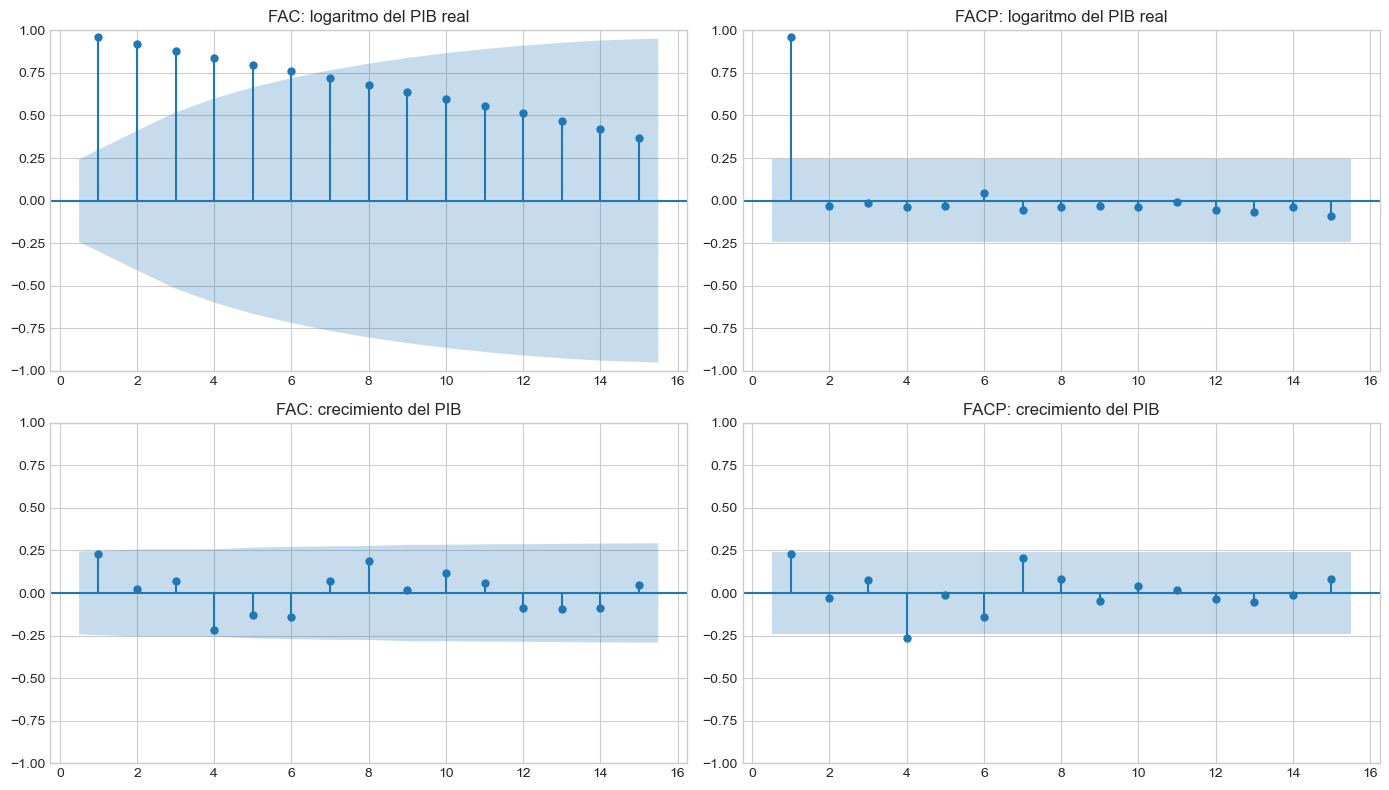

In [8]:
# 8. FAC y FACP del nivel y del crecimiento
serie_nivel = datos['log_pib'].dropna()
serie_crecimiento = datos['crecimiento_pib'].dropna()
max_lags = min(15, len(serie_crecimiento) // 2 - 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(serie_nivel, lags=max_lags, ax=axes[0, 0], zero=False)
axes[0, 0].set_title('FAC: logaritmo del PIB real')

plot_pacf(
    serie_nivel,
    lags=max_lags,
    ax=axes[0, 1],
    zero=False,
    method='ywm',
)
axes[0, 1].set_title('FACP: logaritmo del PIB real')

plot_acf(serie_crecimiento, lags=max_lags, ax=axes[1, 0], zero=False)
axes[1, 0].set_title('FAC: crecimiento del PIB')

plot_pacf(
    serie_crecimiento,
    lags=max_lags,
    ax=axes[1, 1],
    zero=False,
    method='ywm',
)
axes[1, 1].set_title('FACP: crecimiento del PIB')

plt.tight_layout()
plt.show()

📝 **Apunte — el código**

- `serie_nivel = datos['log_pib'].dropna()` → el **nivel** (en logaritmo).
- `serie_crecimiento = datos['crecimiento_pib'].dropna()` → la **diferencia** (crecimiento).
- `max_lags = min(15, len(serie_crecimiento) // 2 - 1)` → se miran hasta 15 rezagos, pero nunca más que la mitad de los datos (con pocos datos, los rezagos largos no son confiables). Con 65 años: min(15, 31) = **15**.
- `plt.subplots(2, 2)` → arriba: FAC y FACP del **nivel**; abajo: FAC y FACP del **crecimiento**.
- `zero=False` → no dibuja el rezago 0 (siempre vale 1, no aporta).
- `method='ywm'` → método de cálculo de la FACP (Yule-Walker); no necesitas cambiarlo.

📊 **Cómo leer los 4 gráficos de la profe**

**Arriba izquierda — FAC del log(PIB):** empieza en **≈ 0,96** y baja **muy lentamente** (0,92; 0,88; … ≈ 0,37 en el rezago 15). Los primeros ~6 rezagos están **fuera de la banda**.
→ Patrón típico de **tendencia / raíz unitaria** ⇒ **no estacionaria**. (Ojo: la banda se ensancha con los rezagos porque statsmodels la ajusta acumulando las autocorrelaciones anteriores; por eso los rezagos altos quedan "dentro" aunque las barras sean grandes.)

**Arriba derecha — FACP del log(PIB):** **un solo pico enorme en el rezago 1 (≈ 0,96)** y luego todo dentro de la banda.
→ Compatible con $X_t \approx 1 \cdot X_{t-1} + \varepsilon_t$: una **caminata aleatoria** (raíz unitaria). "El PIB de este año es casi el del año pasado más un choque".

**Abajo izquierda — FAC del crecimiento:** barras **pequeñas**, casi todas dentro de la banda. El rezago 1 (≈ 0,23) y el 4 (≈ −0,22) quedan **justo en el borde**.
→ Poca dependencia lineal ⇒ compatible con **estacionariedad** y casi con **ruido blanco**.

**Abajo derecha — FACP del crecimiento:** el rezago 1 (≈ 0,23) en el borde y el **rezago 4 (≈ −0,26) apenas fuera**. Una barra aislada que apenas sale puede ser **azar**.

✍️ **Respuesta tipo para la Actividad 2.3** (tres primeros rezagos):
*"En el log del PIB, la FAC en los rezagos 1, 2 y 3 es muy alta (≈ 0,96; 0,92; 0,88) y decae lentamente, señal de tendencia o raíz unitaria; la FACP solo es significativa en el rezago 1 (≈ 0,96). En el crecimiento, la FAC en los rezagos 1 a 3 es baja (≈ 0,23; 0,02; 0,07) y está dentro o en el borde de las bandas, al igual que la FACP; el crecimiento muestra poca persistencia: un buen año no implica que el siguiente también lo sea."*

## 10. Dependencia gráfica mediante diagramas de rezago

Un diagrama de rezago representa $X_t$ frente a $X_{t-k}$:

- nube sin orientación: dependencia lineal débil;
- nube ascendente: autocorrelación positiva;
- nube descendente: autocorrelación negativa;
- forma curva: dependencia no lineal posible;
- grupos separados: quiebres, regímenes o atípicos.

La correlación resume asociación lineal; el gráfico puede mostrar patrones que el coeficiente oculta.

📝 **Apunte:** un **diagrama de rezago** es un gráfico de puntos donde cada punto es un año: en el eje X va el valor **del año anterior** ($X_{t-1}$) y en el eje Y el valor **de ese año** ($X_t$). Es la "foto" de la autocorrelación: el número de la FAC en el rezago 1 es la correlación de esa nube.

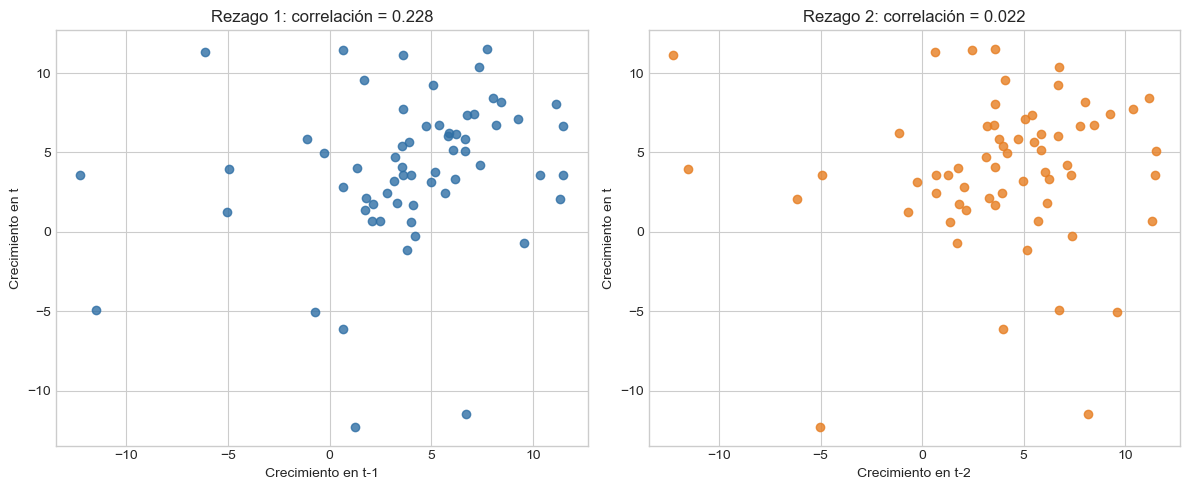

In [9]:
# 9. Diagramas de rezago para el crecimiento
dependencia = pd.DataFrame({'actual': serie_crecimiento})
dependencia['rezago_1'] = dependencia['actual'].shift(1)
dependencia['rezago_2'] = dependencia['actual'].shift(2)
dependencia = dependencia.dropna()

corr_lag1 = dependencia['actual'].corr(dependencia['rezago_1'])
corr_lag2 = dependencia['actual'].corr(dependencia['rezago_2'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    dependencia['rezago_1'],
    dependencia['actual'],
    color='#2F6FA5',
    alpha=0.8,
)
axes[0].set_title(f'Rezago 1: correlación = {corr_lag1:.3f}')
axes[0].set_xlabel('Crecimiento en t-1')
axes[0].set_ylabel('Crecimiento en t')

axes[1].scatter(
    dependencia['rezago_2'],
    dependencia['actual'],
    color='#E67E22',
    alpha=0.8,
)
axes[1].set_title(f'Rezago 2: correlación = {corr_lag2:.3f}')
axes[1].set_xlabel('Crecimiento en t-2')
axes[1].set_ylabel('Crecimiento en t')

plt.tight_layout()
plt.show()

📝 **Apunte — el código**

- `pd.DataFrame({'actual': serie_crecimiento})` → tabla con el crecimiento.
- `.shift(1)` → **corre la columna 1 lugar hacia abajo**: en la fila de 2022 queda el valor de 2021. Así cada fila tiene "este año" y "el año pasado". `.shift(2)` hace lo mismo con 2 años.
- `.dropna()` → bota las primeras filas que quedan sin año anterior.
- `.corr(...)` → correlación entre la columna actual y la rezagada.
- `scatter(x, y, alpha=0.8)` → gráfico de puntos (`alpha` = transparencia).
- `f'Rezago 1: correlación = {corr_lag1:.3f}'` → texto con el número dentro, con 3 decimales.

📊 **Cómo leer los gráficos de la profe**

- **Rezago 1 (correlación = 0,228):** la nube tiene una **leve inclinación hacia arriba**: hay una pequeña tendencia a que a un buen año le siga otro buen año, pero es **débil**. Coincide con la barra del rezago 1 de la FAC (≈ 0,23, en el borde de la banda).
- **Rezago 2 (correlación = 0,022):** nube **sin orientación** → no hay relación entre el crecimiento de un año y el de dos años antes.
- **Puntos aislados**, lejos de la nube principal, como (−12, 3,6) o (6,7, −11,5): son las **crisis** (1975, 1982) y la **pandemia** (2020) con su rebote de 2021. Son **atípicos** que pueden inflar o desinflar la correlación. Por eso la profe dice que el gráfico muestra cosas que el coeficiente oculta.

## 11. Pruebas ADF y KPSS

Las pruebas plantean hipótesis nulas distintas:

### Dickey-Fuller aumentada, ADF

- $H_0$: existe raíz unitaria; la serie no es estacionaria.
- $H_1$: la serie es estacionaria alrededor de los componentes incluidos.

### KPSS

- $H_0$: la serie es estacionaria.
- $H_1$: la serie no es estacionaria.

Lectura conjunta:

| ADF | KPSS | Lectura |
|---|---|---|
| Rechaza $H_0$ | No rechaza $H_0$ | Evidencia favorable a estacionariedad |
| No rechaza $H_0$ | Rechaza $H_0$ | Evidencia favorable a no estacionariedad |
| Ambas rechazan | Resultado conflictivo; revisar quiebres y especificación |
| Ninguna rechaza | Evidencia insuficiente; revisar potencia y muestra |

La conclusión depende de si se incluye constante, tendencia y suficientes rezagos.

📝 **Apunte — pruebas de hipótesis en 30 segundos**

Una prueba parte de una **hipótesis nula $H_0$** ("lo que se supone si no hay evidencia en contra") y entrega un **valor p**:
- **p < 0,05** → hay evidencia suficiente → **se rechaza $H_0$**.
- **p ≥ 0,05** → no hay evidencia suficiente → **no se rechaza $H_0$** (ojo: eso **no demuestra** que $H_0$ sea cierta).

**La trampa de esta sección:** ADF y KPSS tienen la hipótesis nula **al revés**:

| Prueba | $H_0$ (lo que supone) | Si p < 0,05 concluyo… | Si p ≥ 0,05 concluyo… |
|---|---|---|---|
| **ADF** | **NO** estacionaria (raíz unitaria) | ✅ **Estacionaria** | ❌ No puedo decir que sea estacionaria |
| **KPSS** | **SÍ** estacionaria | ❌ **No estacionaria** | ✅ Compatible con estacionaria |

🧠 **Truco para memorizar:**
- **ADF:** p chico = **A**probada como estacionaria.
- **KPSS:** p chico = **K**aput, no es estacionaria.

**Lectura conjunta** (la tabla de la profe):

| ADF | KPSS | Conclusión |
|---|---|---|
| p < 0,05 | p ≥ 0,05 | ✅ **Estacionaria** (ambas coinciden) |
| p ≥ 0,05 | p < 0,05 | ❌ **No estacionaria** (ambas coinciden) |
| p < 0,05 | p < 0,05 | ⚠️ Contradicción: revisar quiebres o la especificación |
| p ≥ 0,05 | p ≥ 0,05 | ⚠️ No concluyente: pocos datos o pruebas con poca potencia |

**"Constante y tendencia":** al hacer la prueba se elige qué incluir:
- `regression='c'` → solo constante: "¿la serie ronda un valor fijo?". Se usa para series **sin tendencia** (como el crecimiento).
- `regression='ct'` → constante **y tendencia**: "¿la serie ronda una **línea con pendiente**?". Se usa para series **con tendencia** (como el log del PIB).

In [10]:
# 10. ADF y KPSS
adf_nivel = adfuller(serie_nivel, regression='ct', autolag='AIC')
kpss_nivel = kpss(serie_nivel, regression='ct', nlags='auto')

adf_crecimiento = adfuller(serie_crecimiento, regression='c', autolag='AIC')
kpss_crecimiento = kpss(serie_crecimiento, regression='c', nlags='auto')

pruebas = pd.DataFrame(
    {
        'ADF estadístico': [adf_nivel[0], adf_crecimiento[0]],
        'ADF p': [adf_nivel[1], adf_crecimiento[1]],
        'KPSS estadístico': [kpss_nivel[0], kpss_crecimiento[0]],
        'KPSS p': [kpss_nivel[1], kpss_crecimiento[1]],
    },
    index=['log(PIB real)', 'crecimiento del PIB'],
)

print(pruebas.round(4))
print('\nRegla con 5%:')
print('- ADF p < 0,05: rechazar raíz unitaria.')
print('- KPSS p < 0,05: rechazar estacionariedad.')

                     ADF estadístico  ADF p  KPSS estadístico  KPSS p
log(PIB real)                 -1.938  0.635             0.166   0.034
crecimiento del PIB           -6.243  0.000             0.105   0.100

Regla con 5%:
- ADF p < 0,05: rechazar raíz unitaria.
- KPSS p < 0,05: rechazar estacionariedad.


C:\Users\beabe\AppData\Local\Temp\ipykernel_21636\1888993785.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_crecimiento = kpss(serie_crecimiento, regression='c', nlags='auto')


📝 **Apunte — el código**

- `adfuller(serie_nivel, regression='ct', autolag='AIC')` → prueba ADF al log del PIB, con constante y tendencia. `autolag='AIC'` elige automáticamente cuántos rezagos incluir (el "aumentada" de Dickey-Fuller aumentada).
- `kpss(serie_nivel, regression='ct', nlags='auto')` → prueba KPSS, también con tendencia.
- Para el crecimiento se usa `regression='c'` (solo constante), porque no tiene tendencia.
- Las pruebas devuelven varios resultados; `[0]` es el **estadístico** y `[1]` es el **valor p**.
- `pd.DataFrame({...}, index=[...])` → arma una tabla de 2 filas (nivel y crecimiento) por 4 columnas.

📊 **Cómo leer la tabla de la profe**

| Serie | ADF p | → ADF dice | KPSS p | → KPSS dice | **Conclusión** |
|---|---|---|---|---|---|
| **log(PIB real)** | **0,635** (≥ 0,05) | No rechaza raíz unitaria | **0,034** (< 0,05) | Rechaza estacionariedad | ❌ **No estacionaria** (coinciden) |
| **Crecimiento del PIB** | **0,000** (< 0,05) | Rechaza raíz unitaria | **0,100** (≥ 0,05) | No rechaza estacionariedad | ✅ **Estacionaria** (coinciden) |

Los estadísticos: el ADF del crecimiento (**−6,243**) es muy negativo, por eso su p es ≈ 0 (en ADF, mientras más negativo, más evidencia de estacionariedad). El ADF del nivel (**−1,938**) es poco negativo.

⚠️ **El mensaje rosado `InterpolationWarning`** que aparece **no es un error**. Dice que el estadístico KPSS quedó fuera de la tabla de valores críticos y que **el valor p real es mayor** que el que muestra (0,100). O sea, el p del crecimiento es **0,10 o más**, con lo que la conclusión ("no se rechaza estacionariedad") queda **aún más firme**.

✍️ **Respuesta tipo para la Actividad 2.4:** *"Para el log del PIB, la ADF no rechaza la raíz unitaria (p = 0,635) y la KPSS rechaza la estacionariedad (p = 0,034): ambas indican que el nivel no es estacionario. Para el crecimiento, la ADF rechaza la raíz unitaria (p ≈ 0) y la KPSS no rechaza la estacionariedad (p ≥ 0,10): ambas indican que el crecimiento es estacionario. Diferenciar el log del PIB, lo que equivale a usar su tasa de crecimiento, resuelve la no estacionariedad."*

## 12. ¿Cómo reconocer ruido blanco?

Una serie compatible con ruido blanco debería presentar:

- media aproximadamente constante;
- varianza estable;
- FAC sin autocorrelaciones sistemáticas;
- prueba de Ljung-Box sin evidencia conjunta de autocorrelación.

El estadístico de Ljung-Box es:

$$Q=n(n+2)\sum_{k=1}^{h}\frac{\widehat\rho_k^2}{n-k}$$

La hipótesis nula establece que las autocorrelaciones hasta $h$ son conjuntamente iguales a cero. Un valor $p$ mayor que 0,05 no demuestra independencia; solo indica que la prueba no detectó autocorrelación conjunta.

📝 **Apunte — Ljung-Box en palabras simples**

La FAC mira los rezagos **uno por uno**. **Ljung-Box** los junta: pregunta si **todas** las autocorrelaciones hasta el rezago *h* son, en conjunto, cero.

- $H_0$: **no hay autocorrelación** hasta *h* (compatible con ruido blanco).
- **p < 0,05** → hay autocorrelación → **no es ruido blanco** (queda estructura que se podría modelar).
- **p ≥ 0,05** → no se detecta autocorrelación → **compatible con ruido blanco**.

En la fórmula, $Q$ suma las autocorrelaciones **al cuadrado** (para que las negativas no cancelen a las positivas): mientras más grande $Q$, más autocorrelación hay y menor es el p.

🔗 **Conexión con Holt-Winters:** en la práctica anterior se revisó la FAC de los **residuos** del modelo ganador. Ljung-Box es la prueba formal de lo mismo: si los residuos de un buen modelo son ruido blanco, el modelo capturó toda la estructura.

In [11]:
# 11. Comparación de Ljung-Box
ljung_ruido = acorr_ljungbox(
    ruido_blanco,
    lags=[10],
    return_df=True,
)

ljung_crecimiento = acorr_ljungbox(
    serie_crecimiento,
    lags=[10],
    return_df=True,
)

print('Ruido blanco simulado')
print(ljung_ruido.round(4))
print('\nCrecimiento del PIB de Chile')
print(ljung_crecimiento.round(4))

Ruido blanco simulado
    lb_stat  lb_pvalue
10   14.412      0.155

Crecimiento del PIB de Chile
    lb_stat  lb_pvalue
10   14.018      0.172


📝 **Apunte — el código**

- `acorr_ljungbox(serie, lags=[10], return_df=True)` → prueba de Ljung-Box usando los primeros **10 rezagos**, con el resultado en tabla.
- La tabla tiene `lb_stat` (el estadístico $Q$) y `lb_pvalue` (el valor p).

📊 **Cómo leer el resultado de la profe**

| Serie | Q | p | Conclusión |
|---|---|---|---|
| Ruido blanco simulado | 14,412 | **0,155** | p ≥ 0,05 → no se detecta autocorrelación ✅ (como debe ser) |
| Crecimiento del PIB de Chile | 14,018 | **0,172** | p ≥ 0,05 → **compatible con ruido blanco** ✅ |

**Interpretación económica:** las autocorrelaciones del crecimiento del PIB, en conjunto, no son significativas. **El crecimiento de un año casi no ayuda a predecir el del año siguiente** con un modelo lineal. Coincide con la FAC (barras en el borde) y el diagrama de rezago (correlación 0,23).

⚠️ La profe advierte: p > 0,05 **no demuestra** independencia; solo dice que la prueba **no detectó** autocorrelación. (Con solo 65 años de datos la prueba tiene poca "potencia".)

🔁 **Si me piden otro número de rezagos:** cambia `lags=[10]` por, por ejemplo, `lags=[5]` o `lags=[5, 10, 15]` (una fila por cada uno).

## 13. Práctica guiada

### Actividad 1: ruido blanco y caminata aleatoria

1. Cambie la semilla aleatoria.
2. Compare la FAC del ruido blanco y la caminata.
3. Diferencie la caminata y vuelva a graficar su FAC.
4. Explique por qué una trayectoria visualmente suave puede ser no estacionaria.

### Actividad 2: datos del Banco Mundial

1. Describa el PIB real y su crecimiento sin aplicar pruebas.
2. Compare media y varianza móviles.
3. Interprete los tres primeros rezagos de la FAC y la FACP.
4. Contraste ADF y KPSS.
5. Redacte una conclusión de máximo 150 palabras.

### Actividad 3: cambiar país

Reemplace `CHL` por `ARG`, `PER`, `COL`, `MEX` o `BRA`. Compare:

- años disponibles;
- volatilidad del crecimiento;
- resultados ADF y KPSS;
- forma de la FAC y FACP;
- observaciones extremas y posibles quiebres.

📝 **Apunte — cómo resolver la práctica con los códigos de la profe**

**Actividad 1 (simulados)**
1. *Cambie la semilla:* en la celda **2. Simulación reproducible**, cambia `2026` en `np.random.default_rng(2026)` y ejecuta todo de nuevo.
2. *Compare la FAC del ruido y la caminata:* la celda **12. Ejercicio resuelto** (más abajo) ya grafica la FAC de la caminata con `plot_acf(caminata_aleatoria, ...)`. Para el ruido es **la misma línea cambiando el nombre de la variable** por `ruido_blanco`.
3. *Diferencie la caminata y grafique su FAC:* es exactamente la celda **12. Ejercicio resuelto**.
4. *¿Por qué una trayectoria suave puede ser no estacionaria?* → ver el apunte después del gráfico de la simulación.

**Actividad 2 (Banco Mundial):** en cada sección dejé una **✍️ Respuesta tipo** con los números de la profe (2.1 en la sección 5, 2.2 en la 6, 2.3 en la 9, 2.4 en la 11). La conclusión de 150 palabras está al final, en la plantilla.

**Actividad 3 (otro país):** cambia `CHL` en **las dos URL** de la celda de descarga y vuelve a ejecutar todo. Compara con Chile:
- **Años disponibles:** lo dice `Número de años`.
- **Volatilidad:** mira el gráfico de crecimiento y la varianza móvil (Argentina, por ejemplo, suele ser mucho más volátil).
- **ADF y KPSS:** la tabla de pruebas.
- **FAC y FACP**, **atípicos y quiebres:** los gráficos.

In [ ]:
# 12. Ejercicio resuelto: diferenciar la caminata aleatoria
diferencia_caminata = np.diff(caminata_aleatoria)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(caminata_aleatoria, lags=20, ax=axes[0], zero=False)
axes[0].set_title('FAC de la caminata aleatoria')
plot_acf(diferencia_caminata, lags=20, ax=axes[1], zero=False)
axes[1].set_title('FAC de la primera diferencia')
plt.tight_layout()
plt.show()

print('¿Coincide la diferencia con el ruido original?',
      np.allclose(diferencia_caminata, ruido_blanco[1:]))

📝 **Apunte — el ejercicio resuelto**

- `np.diff(caminata_aleatoria)` → la **primera diferencia**: cada valor menos el anterior. Deja 249 datos (uno menos).
- Dos gráficos lado a lado (`plt.subplots(1, 2)`): FAC de la caminata y FAC de su diferencia, con 20 rezagos.
- `np.allclose(diferencia_caminata, ruido_blanco[1:])` → compara si la diferencia es igual al ruido original **desde el segundo valor** (`[1:]`). Imprime **`True`**, que es la comprobación numérica de $\Delta X_t = \varepsilon_t$.

📊 **Qué vas a ver al ejecutarla** (lo comprobé con la misma semilla 2026)

- **FAC de la caminata:** barras **muy altas** que bajan **lentamente** (≈ 0,97 en el rezago 1, ≈ 0,46 en el 19). Es el mismo patrón que la FAC del **log del PIB** → **raíz unitaria, no estacionaria**.
- **FAC de la primera diferencia:** barras **pequeñas**, casi todas **dentro** de la banda (en el rezago 1 ≈ 0,10). Alguna barra aislada, como la del rezago 4 (≈ −0,14), puede quedar apenas fuera **por azar**. Es el patrón del **ruido blanco** → **estacionaria**.

✅ **La moraleja de toda la clase:** caminata aleatoria → se diferencia → ruido blanco. **Log(PIB) → se diferencia → crecimiento**, con el mismo resultado: de no estacionaria a estacionaria.

## 14. Plantilla para la conclusión técnica

> La serie en nivel presenta ________, por lo que la media parece ________. La FAC muestra ________. Las pruebas ADF y KPSS entregan ________. Después de aplicar ________, la serie muestra ________. Por tanto, para el modelamiento posterior se recomienda ________. Esta conclusión debe complementarse con la revisión de quiebres, atípicos y contexto económico.

## Bibliografía básica

- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. y Ljung, G. M. *Time Series Analysis: Forecasting and Control*.
- Brockwell, P. J. y Davis, R. A. *Introduction to Time Series and Forecasting*.
- Hamilton, J. D. *Time Series Analysis*.
- Hyndman, R. J. y Athanasopoulos, G. *Forecasting: Principles and Practice*.
- Banco Mundial. Indicators API V2 y World Development Indicators.

### Enlaces oficiales

- API: https://api.worldbank.org/v2/
- Documentación: https://datahelpdesk.worldbank.org/knowledgebase/articles/889392
- PIB real: https://data.worldbank.org/indicator/NY.GDP.MKTP.KD
- Crecimiento del PIB: https://data.worldbank.org/indicator/NY.GDP.MKTP.KD.ZG

📝 **Apunte — la plantilla completada con los resultados de la profe** (Actividad 2.5, ≤ 150 palabras)

> La serie en nivel presenta **una tendencia creciente persistente**, por lo que la media parece **no constante**. La FAC muestra **autocorrelaciones cercanas a 1 que decaen lentamente, y la FACP un único pico en el rezago 1, lo que es típico de una raíz unitaria**. Las pruebas ADF y KPSS entregan **evidencia coincidente de no estacionariedad en el nivel (ADF p = 0,635; KPSS p = 0,034)**. Después de aplicar **logaritmo y primera diferencia, es decir, la tasa de crecimiento**, la serie muestra **una media estable cercana a 4%, autocorrelaciones pequeñas y pruebas favorables a la estacionariedad (ADF p ≈ 0; KPSS p ≥ 0,10)**. Por tanto, para el modelamiento posterior se recomienda **trabajar con el crecimiento del PIB y no con su nivel**. Esta conclusión debe complementarse con la revisión de quiebres, atípicos y contexto económico, en particular las crisis de 1975 y 1982, la pandemia de 2020 y la mayor volatilidad antes de 1990.

---
# 🧾 Chuleta de la clase

### Lo que hace cada herramienta

| Herramienta | Código | Pregunta que responde | Estacionaria si… |
|---|---|---|---|
| Gráfico | `plt.plot` | ¿Tendencia, cambios de varianza, quiebres? | Ronda un valor fijo con oscilaciones parecidas |
| Media/varianza móvil | `.rolling(10).mean()` / `.var()` | ¿Cambian la media o la varianza en el tiempo? | Las líneas móviles son planas |
| FAC | `plot_acf` | ¿Cuánto se parece la serie a su pasado? | Las barras caen rápido o quedan dentro de la banda |
| FACP | `plot_pacf` | ¿Relación directa con cada rezago? | Sin pico enorme en el rezago 1 |
| Diagrama de rezago | `.shift(1)` + `scatter` | ¿Se ve la dependencia? | Nube sin orientación (o leve) |
| ADF | `adfuller` | ¿Hay raíz unitaria? | **p < 0,05** |
| KPSS | `kpss` | ¿Es estacionaria? | **p ≥ 0,05** |
| Ljung-Box | `acorr_ljungbox` | ¿Es ruido blanco? | (ruido blanco si **p ≥ 0,05**) |

### Cómo arreglar una serie no estacionaria
- **Tendencia o raíz unitaria** → **diferenciar** (`.diff()` o `np.diff`).
- **Varianza que crece con el nivel** → **logaritmo** (`np.log`), y luego diferenciar si hay tendencia.
- Log + diferencia ≈ **tasa de crecimiento** (× 100 = %).

### 🔁 Lo que cambia si me cambian los datos
| Qué | Dónde |
|---|---|
| País | `CHL` en **las dos** URL (`url_nivel` y `url_crecimiento`) |
| Indicador | `NY.GDP.MKTP.KD` / `NY.GDP.MKTP.KD.ZG` en las URL (y los títulos) |
| Años | `'date': '1960:2030'` |
| Semilla de la simulación | `np.random.default_rng(2026)` |
| Largo de la simulación | `n = 250` |
| Ventana móvil | `ventana = 10` |
| Rezagos de FAC/FACP | `max_lags` (o `lags=20` en el ejercicio resuelto) |
| Rezagos de Ljung-Box | `lags=[10]` |
| Con o sin tendencia en las pruebas | `regression='ct'` (con tendencia) o `'c'` (sin) |

### ⚠️ Errores típicos
| Error | Causa | Solución |
|---|---|---|
| `OSError: 'seaborn-v0_8-whitegrid' not found` | matplotlib antiguo | `%pip install -U matplotlib` |
| `ModuleNotFoundError: statsmodels` | Falta paquete | `%pip install statsmodels` |
| `RuntimeError: La API no devolvió…` | Sin internet o país sin datos | Revisar conexión / otro país |
| `InterpolationWarning` en KPSS | p fuera de la tabla | **No es error**: el p real es más extremo que el mostrado |
| `NameError` | No ejecutaste celdas anteriores | Ejecutar desde arriba |
| `ValueError: log of zero/negative` | Serie con ceros o negativos | No usar log en esa serie (ej.: el crecimiento puede ser negativo, ¡no se le saca log!) |

---
✅ **Autoevaluación**

<details><summary>1. ¿Cuál es la diferencia entre un proceso estocástico y una serie de tiempo?</summary>

El proceso estocástico es el **mecanismo aleatorio** (una variable aleatoria $X_t$ por cada período). La serie de tiempo es **la realización observada** de ese proceso: los números $x_1, \ldots, x_n$ que tenemos.
</details>

<details><summary>2. Nombra las 3 condiciones de la estacionariedad débil.</summary>

1) Media constante; 2) varianza finita y constante; 3) covarianza que depende solo del rezago *k*, no del momento *t*.
</details>

<details><summary>3. ¿Por qué la caminata aleatoria no es estacionaria y cómo se arregla?</summary>

Porque los choques se acumulan ($X_t = X_{t-1} + \varepsilon_t$): no vuelve a una media fija y su varianza crece con el tiempo. Se arregla **diferenciando**: $\Delta X_t = \varepsilon_t$ es ruido blanco.
</details>

<details><summary>4. ADF da p = 0,40 y KPSS da p = 0,01. ¿Conclusión?</summary>

ADF no rechaza la raíz unitaria y KPSS rechaza la estacionariedad: ambas coinciden en que la serie **no es estacionaria**.
</details>

<details><summary>5. ADF da p = 0,01 y KPSS da p = 0,20. ¿Conclusión?</summary>

ADF rechaza la raíz unitaria y KPSS no rechaza la estacionariedad: la serie es **estacionaria**.
</details>

<details><summary>6. ADF da p = 0,01 y KPSS da p = 0,02. ¿Conclusión?</summary>

Resultado **conflictivo**: una dice estacionaria y la otra no. Hay que revisar quiebres estructurales, atípicos y si se incluyó correctamente constante o tendencia.
</details>

<details><summary>7. La FAC empieza en 0,95 y baja muy lento. La FACP tiene un solo pico de 0,95 en el rezago 1. ¿Qué serie es probablemente?</summary>

Una serie con **raíz unitaria / tendencia** (como una caminata aleatoria o el log del PIB). No es estacionaria; hay que diferenciarla.
</details>

<details><summary>8. La FACP se corta después del rezago 2 y la FAC decae gradualmente. ¿Qué modelo sugiere?</summary>

Un **AR(2)** (autorregresivo de orden 2).
</details>

<details><summary>9. Ljung-Box con 10 rezagos da p = 0,01 para los residuos de un modelo. ¿Qué significa?</summary>

Que **hay autocorrelación conjunta** en los residuos: no son ruido blanco y el modelo **dejó estructura sin capturar**.
</details>

<details><summary>10. ¿Por qué se usa regression='ct' para el log del PIB y 'c' para el crecimiento?</summary>

Porque el log del PIB tiene **tendencia**, así que se prueba si es estacionario alrededor de una tendencia (constante + tendencia). El crecimiento no tiene tendencia, así que basta con la constante.
</details>

<details><summary>11. ¿Por qué 100 × (log PIB hoy − log PIB año pasado) se parece al crecimiento %?</summary>

Porque $\ln(PIB_t/PIB_{t-1}) = \ln(1+g) \approx g$ cuando *g* es pequeño. Por eso la aproximación es peor en años de cambios grandes (2021: 11,34% vs 10,74%).
</details>

<details><summary>12. ¿Una serie no normal puede ser estacionaria?</summary>

Sí. Normalidad (forma de la distribución) y estacionariedad (estabilidad en el tiempo) son conceptos distintos.
</details>

**¡Mucho éxito! 💪**